In [8]:
"""
Practical Engineering Case Study: Supervised Machine Learning Classification
Algorithms:
1. Support Vector Machines (SVM)
2. Naïve Bayes (Gaussian Naïve Bayes)
3. Decision Tree
4. Random Forest
5. AdaBoost
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

In [9]:
# ============================================================
# PART 1. CREATE DATASET (30 RECORDS)
# ============================================================

data = {
    'Machine_ID': [
        'M001', 'M002', 'M003', 'M004', 'M005',
        'M006', 'M007', 'M008', 'M009', 'M010',
        'M011', 'M012', 'M013', 'M014', 'M015',
        'M016', 'M017', 'M018', 'M019', 'M020',
        'M021', 'M022', 'M023', 'M024', 'M025',
        'M026', 'M027', 'M028', 'M029', 'M030'
    ],

    'Temperature_C': [
        58, 62, 65, 60, 68, 63, 70, 57, 66, 61,
        72, 75, 78, 74, 80, 76, 79, 73, 77, 81,
        85, 88, 83, 91, 86, 89, 84, 93, 87, 95
    ],

    'Vibration_mm_s': [
        1.4, 1.8, 2.1, 1.6, 2.4, 1.9, 2.2, 1.3, 2.0, 1.7,
        3.2, 3.5, 3.8, 3.4, 4.0, 3.6, 3.9, 3.3, 3.7, 4.1,
        5.8, 6.5, 5.5, 7.1, 6.2, 6.8, 5.9, 7.3, 6.4, 7.8
    ],

    'Speed_RPM': [
        1750, 1680, 1720, 1800, 1650, 1700, 1600, 1780, 1690, 1740,
        1550, 1500, 1480, 1530, 1450, 1510, 1470, 1560, 1490, 1430,
        1350, 1280, 1400, 1200, 1320, 1250, 1380, 1190, 1300, 1150
    ],

    'Operating_Hours': [
        800, 1200, 1500, 950, 1800, 1100, 2000, 700, 1600, 1300,
        2500, 2800, 3200, 2700, 3500, 3000, 3300, 2600, 3100, 3700,
        5200, 6800, 4900, 7900, 6100, 7200, 5700, 8800, 6500, 9200
    ],
    'Failure_Risk': [
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1,

    2, 2, 2, 2, 2,
    2, 2, 2, 2, 2,

    3, 3, 3, 3, 3,
    3, 3, 3, 3, 3
]
}

columns = [
    "Machine_ID",
    "Temperature_C",
    "Vibration_mm_s",
    "Speed_RPM",
    "Operating_Hours",
    "Failure_Risk"
]

df = pd.DataFrame(data, columns=columns)

print("\nDATASET: 30 MACHINE RECORDS")
print(df.to_string(index=False))

print("\nClass distribution:")
print(
    df["Failure_Risk"]
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Normal",
        2: "Warning",
        3: "Failure Risk"
    })
)


DATASET: 30 MACHINE RECORDS
Machine_ID  Temperature_C  Vibration_mm_s  Speed_RPM  Operating_Hours  Failure_Risk
      M001             58             1.4       1750              800             1
      M002             62             1.8       1680             1200             1
      M003             65             2.1       1720             1500             1
      M004             60             1.6       1800              950             1
      M005             68             2.4       1650             1800             1
      M006             63             1.9       1700             1100             1
      M007             70             2.2       1600             2000             1
      M008             57             1.3       1780              700             1
      M009             66             2.0       1690             1600             1
      M010             61             1.7       1740             1300             1
      M011             72             3.2      

In [10]:
# Separate predictors (X) and target (y).
feature_cols = ["Temperature_C", "Vibration_mm_s", "Speed_RPM", "Operating_Hours"]
X = df[feature_cols]
y = df["Failure_Risk"]

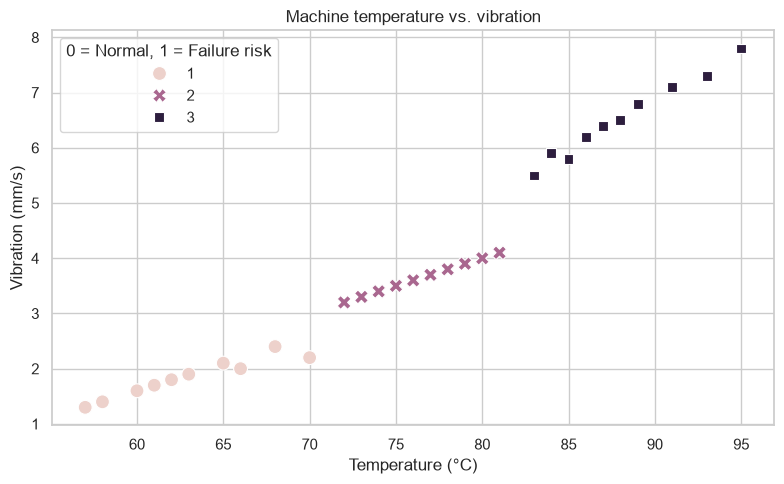

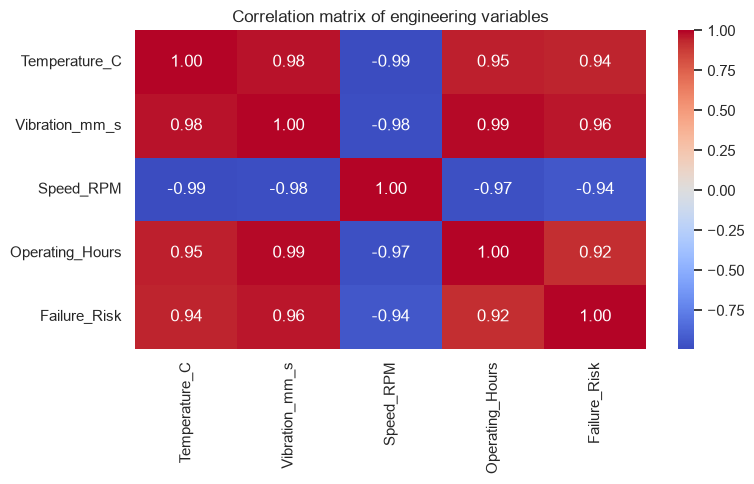

In [11]:
# Initial data visualization.
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="Temperature_C", y="Vibration_mm_s",
    hue="Failure_Risk", style="Failure_Risk", s=100
)
plt.title("Machine temperature vs. vibration")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration (mm/s)")
plt.legend(title="0 = Normal, 1 = Failure risk")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(df[feature_cols + ["Failure_Risk"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix of engineering variables")
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# PART 2. TRAIN-TEST SPLIT
# ============================================================

# Stratification preserves the class ratio in both subsets.
# With only 30 records, test metrics will be highly sensitive to individual records.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"\nTraining records: {len(X_train)}")
print(f"Testing records:  {len(X_test)}")



Training records: 21
Testing records:  9


In [19]:
# ============================================================
# PART 3. DEFINE FIVE INDEPENDENT CLASSIFIERS
# ============================================================

# SVM: scaling is important because SVM uses distances/margins.
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

# Gaussian Naive Bayes: assumes feature values are conditionally Gaussian
# and conditionally independent given the class.
naive_bayes_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", GaussianNB())
])

# Decision Tree: learns a sequence of feature-based splitting rules.
decision_tree_model = DecisionTreeClassifier(
    max_depth=3, random_state=42
)

# Random Forest: combines many decision trees trained on bootstrap samples.
random_forest_model = RandomForestClassifier(
    n_estimators=100, max_depth=3, random_state=42
)

# AdaBoost: sequentially trains weak learners, emphasizing previously
# misclassified training examples.
# SAMME is explicitly selected for compatibility across sklearn versions.
adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)

models = {
    "SVM": svm_model,
    "Naive Bayes": naive_bayes_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "AdaBoost": adaboost_model
}



SVM
Accuracy : 0.889
Precision: 0.917
Recall   : 0.889
F1-score : 0.886

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.67      0.80         3
     Warning       0.75      1.00      0.86         3
Failure Risk       1.00      1.00      1.00         3

    accuracy                           0.89         9
   macro avg       0.92      0.89      0.89         9
weighted avg       0.92      0.89      0.89         9



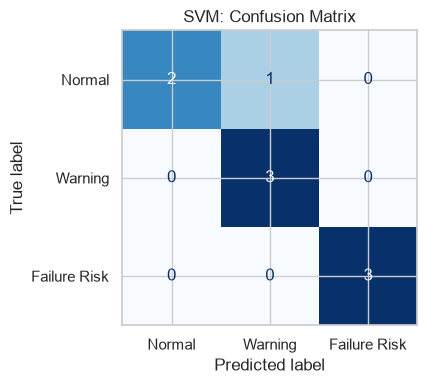


NAIVE BAYES
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1-score : 1.000

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         3
     Warning       1.00      1.00      1.00         3
Failure Risk       1.00      1.00      1.00         3

    accuracy                           1.00         9
   macro avg       1.00      1.00      1.00         9
weighted avg       1.00      1.00      1.00         9



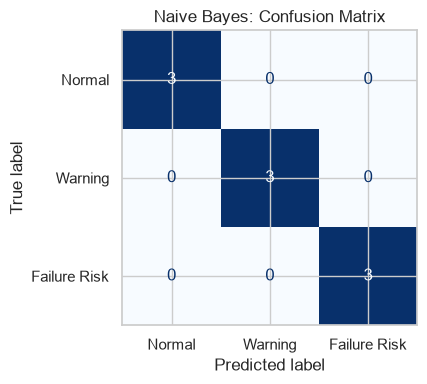


DECISION TREE
Accuracy : 0.889
Precision: 0.917
Recall   : 0.889
F1-score : 0.886

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.67      0.80         3
     Warning       0.75      1.00      0.86         3
Failure Risk       1.00      1.00      1.00         3

    accuracy                           0.89         9
   macro avg       0.92      0.89      0.89         9
weighted avg       0.92      0.89      0.89         9



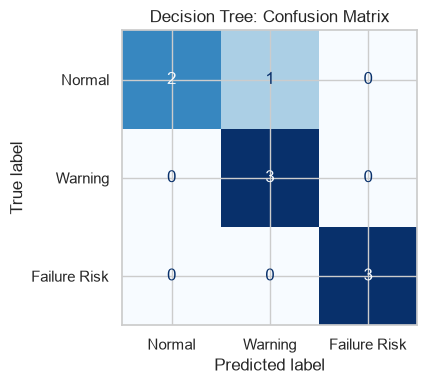


RANDOM FOREST
Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1-score : 1.000

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00         3
     Warning       1.00      1.00      1.00         3
Failure Risk       1.00      1.00      1.00         3

    accuracy                           1.00         9
   macro avg       1.00      1.00      1.00         9
weighted avg       1.00      1.00      1.00         9



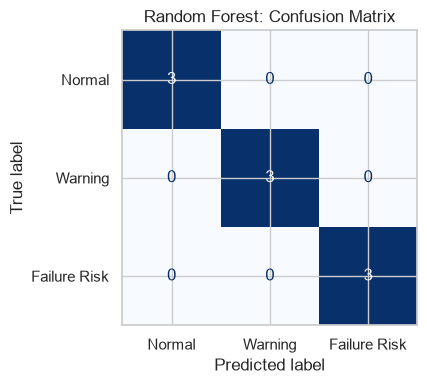


ADABOOST
Accuracy : 0.889
Precision: 0.917
Recall   : 0.889
F1-score : 0.886

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.67      0.80         3
     Warning       0.75      1.00      0.86         3
Failure Risk       1.00      1.00      1.00         3

    accuracy                           0.89         9
   macro avg       0.92      0.89      0.89         9
weighted avg       0.92      0.89      0.89         9



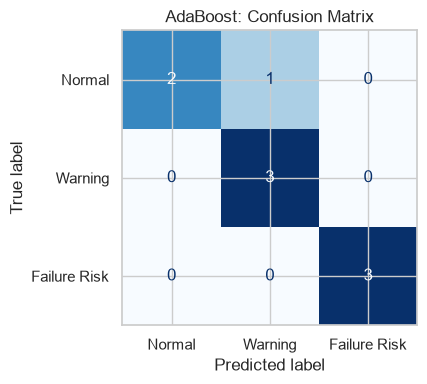

In [20]:

# ============================================================
# PART 4. TRAIN, PREDICT, EVALUATE, AND VISUALIZE EACH MODEL
# ============================================================

results = []
predictions = {}

class_labels = [1, 2, 3]
class_names = ["Normal", "Warning", "Failure Risk"]

for model_name, model in models.items():
    print("\n" + "=" * 65)
    print(f"{model_name.upper()}")
    print("=" * 65)

    # Learn from the training records.
    model.fit(X_train, y_train)

    # Predict labels for unseen test records.
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    # Calculate evaluation metrics for three classes.
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )

    results.append({
        "Algorithm": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1-score : {f1:.3f}")

    print("\nClassification report:")

    print(classification_report(
        y_test, y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

    # Confusion matrix visualization.
    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=class_labels,
        display_labels=class_names,
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{model_name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()



MODEL COMPARISON
               Accuracy  Precision  Recall  F1-score
Algorithm                                           
SVM               0.889      0.917   0.889     0.886
Naive Bayes       1.000      1.000   1.000     1.000
Decision Tree     0.889      0.917   0.889     0.886
Random Forest     1.000      1.000   1.000     1.000
AdaBoost          0.889      0.917   0.889     0.886


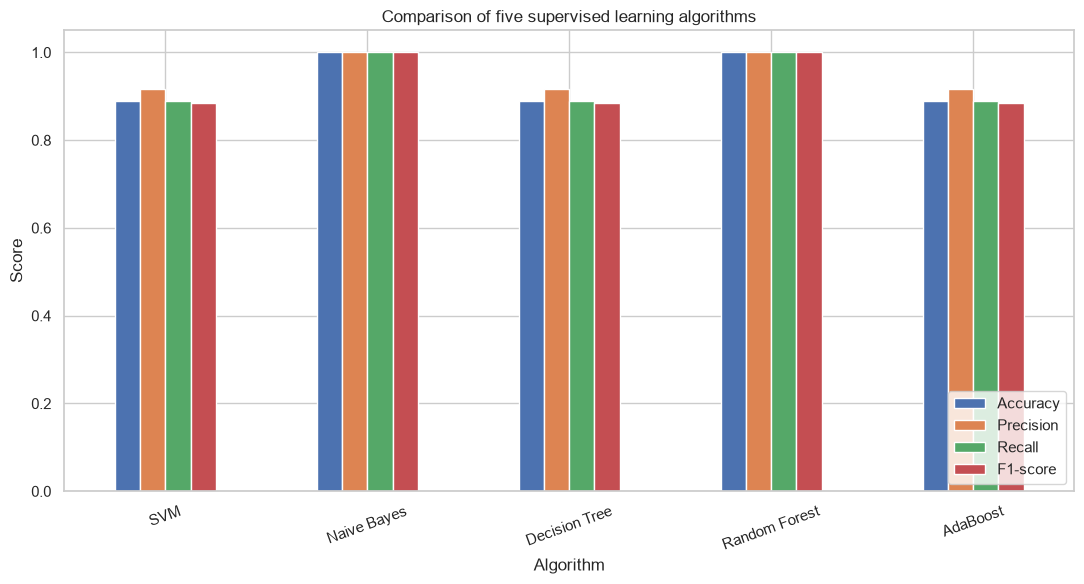

In [24]:
# ============================================================
# PART 5. COMPARE THE FIVE ALGORITHMS
# ============================================================

results_df = pd.DataFrame(results).set_index("Algorithm")
print("\nMODEL COMPARISON")
print(results_df.round(3))

results_df.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Comparison of five supervised learning algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Decision Tree feature importance:
Temperature_C      1.0
Vibration_mm_s     0.0
Speed_RPM          0.0
Operating_Hours    0.0
dtype: float64


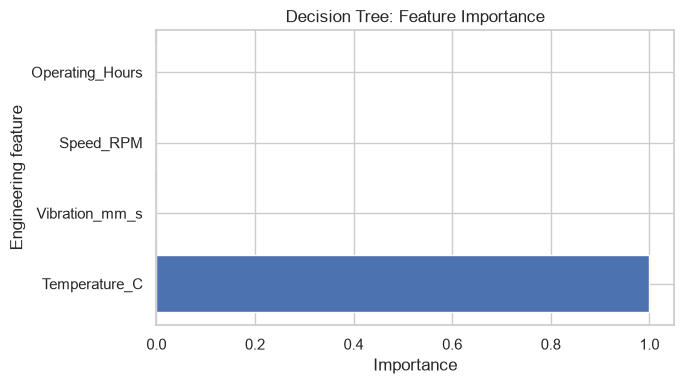


Random Forest feature importance:
Vibration_mm_s     0.270
Temperature_C      0.253
Speed_RPM          0.244
Operating_Hours    0.233
dtype: float64


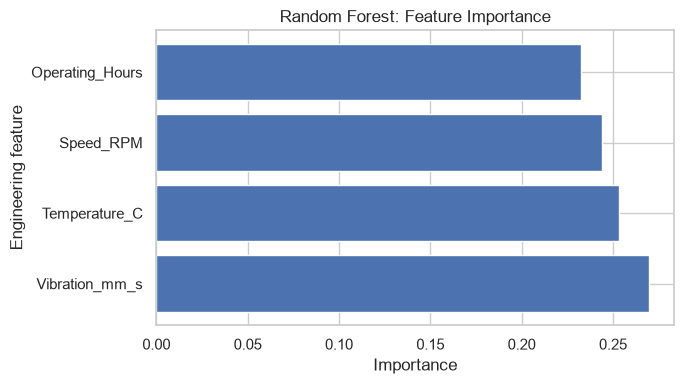

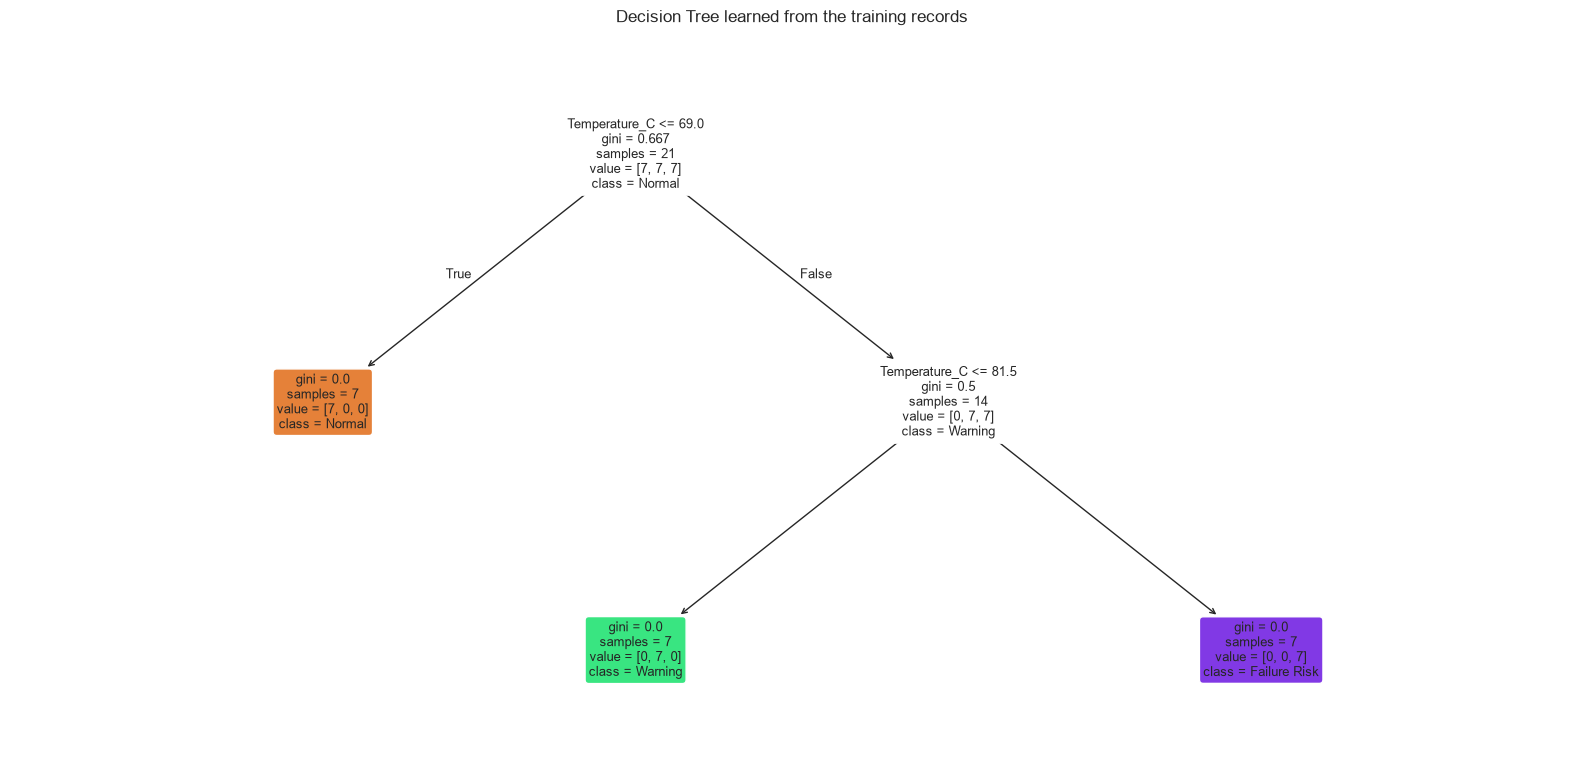

In [25]:

# ============================================================
# PART 6. INTERPRET TREE-BASED FEATURE IMPORTANCE
# ============================================================

tree_models = {
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

for name, model in tree_models.items():

    importance = pd.Series(
        model.feature_importances_,
        index=feature_cols
    ).sort_values(ascending=False)

    print(f"\n{name} feature importance:")
    print(importance.round(3))

    plt.figure(figsize=(7, 4))
    plt.barh(importance.index, importance.values)

    plt.title(f"{name}: Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Engineering feature")

    plt.tight_layout()
    plt.show()

# Visualize the learned Decision Tree.
plt.figure(figsize=(16, 8))

plot_tree(
    decision_tree_model,
    feature_names=feature_cols,
    class_names=["Normal", "Warning", "Failure Risk"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree learned from the training records")
plt.tight_layout()
plt.show()


In [26]:

# ============================================================
# PART 7. TEST A NEW ENGINEERING OBSERVATION
# ============================================================

# Example values are illustrative, not a real machine diagnosis.

new_machine = pd.DataFrame([{
    "Temperature_C": 89,
    "Vibration_mm_s": 6.8,
    "Speed_RPM": 1325,
    "Operating_Hours": 6500
}])

print("\nNEW MACHINE OBSERVATION")
print(new_machine)

# Convert predicted numbers into machine condition names.
class_names = {
    1: "Normal",
    2: "Warning",
    3: "Failure Risk"
}

for name, model in models.items():

    predicted_class = int(model.predict(new_machine)[0])

    label = class_names[predicted_class]

    print(f"{name:15s} prediction: {label}")

print("\nEND OF PRACTICAL CASE STUDY")



NEW MACHINE OBSERVATION
   Temperature_C  Vibration_mm_s  Speed_RPM  Operating_Hours
0             89             6.8       1325             6500
SVM             prediction: Failure Risk
Naive Bayes     prediction: Failure Risk
Decision Tree   prediction: Failure Risk
Random Forest   prediction: Failure Risk
AdaBoost        prediction: Failure Risk

END OF PRACTICAL CASE STUDY
